In [5]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import re, time, sys, os
import pickle
from urllib import parse
import networkx as nx

import mols2grid
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem import AllChem, rdCoordGen, Draw
from rdkit.Chem import rdChemReactions as Reactions
from rdkit.Chem.Draw import rdMolDraw2D

from IPython.display import clear_output
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 800, 500
PandasTools.RenderImagesInAllDataFrames(images=True)
IPythonConsole.drawOptions.AddAtomIndices = False
from rdkit.Chem.Draw import rdDepictor
rdDepictor.SetPreferCoordGen(True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Remove modifications from the NP database

In [6]:
# Load the BUL (Biological unit library)
with open('data/BUL_names.pkl', 'rb') as f:
    BUL_dict = pickle.load(f)
    
# Modifications to the NP database are not needed
print(f'Size before removing: {len(BUL_dict)}')
BUL_dict_copy = {k:v for k, v in BUL_dict.items()}
for names, mol in BUL_dict.items():
    if len(names) == 1:
        if 'mod' in names[0]:
            del BUL_dict_copy[names]
            
BUL_dict = BUL_dict_copy
print(f'Size after removing: {len(BUL_dict)}')

with open('data/BUL_dict.pkl', 'wb') as file:
    pickle.dump(BUL_dict, file, protocol=pickle.HIGHEST_PROTOCOL)

Size before removing: 20035
Size after removing: 18409


# Fragment molecule with GEASS

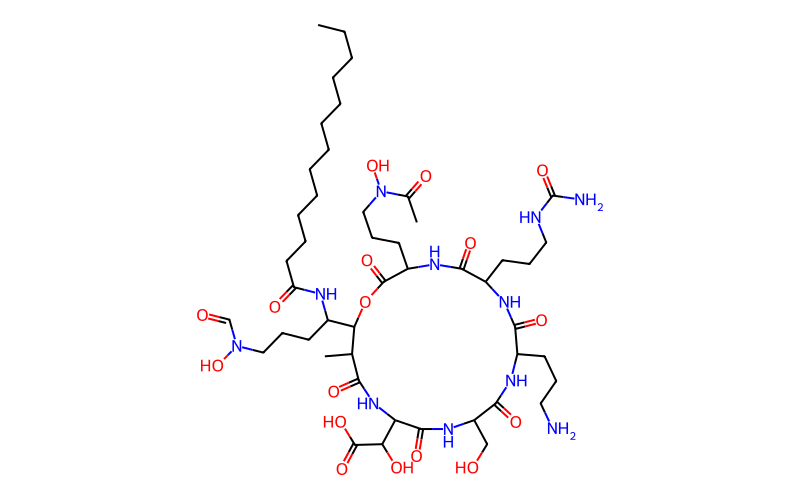

ModuleNotFoundError: No module named 'new_geass'

In [8]:
with open('to_metadisassembler_v3/original_molecules.pkl', 'rb') as f:
    mols = pickle.load(f)
    
import random
mol = random.choice(mols)
display(mol)

# Initialize the GEASS fragmenter
import new_geass
fragmenter = new_geass.Geass(mol)

# Detect the breakable bonds
bond_list = fragmenter.get_bonds_to_break()

# Create a graph (networkx-like) containing the fragments of the molecule
frag_mols = fragmenter.get_fragments()
display(*frag_mols)
print(type(fragmenter.graph))
print('Number of nodes: ', len(fragmenter.graph.nodes))
print('Number of edges: ', len(fragmenter.graph.edges))
print('Node Attributes ', fragmenter.graph.nodes[0].keys())

# Plot the graph
# NP nodes will be plotted in green, otherwise they will be shown in red
# fragmenter.plot_graph()

In [ ]:
rxn = AllChem.ReactionFromSmarts("[C:1]=!@[C:2]>>[C:1].[C:2]")
display(*rxn.RunReactants((mol,))[0])

# Success analysis

In [ ]:
# start_from = 0
# results = {}
# for i, mol in enumerate(mols[start_from:]):
#     j = i + start_from
#     print(f'Progress [{j}/{len(mols)-1}]', end='\r')
#     fragmenter = geass.Geass(mol, brokenBondsDefs, reactants, fillingAtoms, BUL_dict, verbose=0)
#     fragmenter.get_bonds_to_break()
#     fragmenter.create_fragmentation_graph()
#     NPs = nx.get_node_attributes(fragmenter.graph, 'isNP')
#     results[j] = {'NP': len([node for node, isNP in NPs.items() if isNP == 'Yes']),
#                  'NotNP': len([node for node, isNP in NPs.items() if isNP == 'No'])}
# success = len([k for k, v in results.items() if v['NotNP'] == 0])
# print(f'Success rate: {success/len(results)}' )
# rates = {k:v['NP']/(v['NP'] + v['NotNP']) for k, v in results.items() if v['NP'] + v['NotNP'] != 0}
# import seaborn as sns
# sns.histplot(rates.values(), bins = 50)
# import numpy as np
# np.mean(list(rates.values()))